# Prétraitement et extraction de caractéristiques

**Projet :** BrainScanAI - détection semi-supervisée de tumeurs cérébrales  
**Étape :** 2 - Prétraitez et extrayez les features  
**Auteur :** Kilian Lefevre

---

## Objectif du notebook

Les images dédupliquées sont transformées en **vecteurs de caractéristiques** à l'aide d'un modèle pré-entraîné, pour l'analyse non supervisée de l'étape suivante. Ce notebook répond aux questions suivantes :

- Les images ont-elles des particularités (couleur, luminosité, fond) qui pourraient biaiser la suite ?
- Quel prétraitement adopter pour le modèle choisi ?
- Quelles couches du modèle fournissent les caractéristiques les plus exploitables ?
- Les vecteurs produits sont-ils valides, alignés avec le manifeste et sauvegardés dans un format réutilisable ?
- Quel est le coût de calcul, pour anticiper un passage à l'échelle ?

**Prérequis :** le manifeste dédupliqué (`data/interim/manifest.csv`), produit par `make data`. Les données brutes restent **immuables**.

## 1. Chargement du manifeste

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image, ImageOps
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import silhouette_score
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from brain_mri.config import (
    FIGURES_DIR,
    INTERIM_DATA_DIR,
    PROCESSED_DATA_DIR,
    RAW_DATA_DIR,
)
from brain_mri.dataset import EXCLUDED_IMAGES, build_inventory, read_manifest
from brain_mri.features import (
    IMAGE_SIZE,
    IMAGENET_MEAN,
    IMAGENET_STD,
    extract_features,
    load_extractor,
    load_features,
    preprocess_equalized,
    preprocess_gray,
    preprocess_rgb,
    save_features,
    select_device,
)

pd.set_option("display.max_colwidth", 100)
plt.style.use("seaborn-v0_8-whitegrid")

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DATA_DIR.mkdir(parents=True, exist_ok=True)

manifest = read_manifest(INTERIM_DATA_DIR / "manifest.csv")
print(
    f"{len(manifest):,} images, dont {manifest['is_labeled'].sum():,} annotées."
)
display(manifest.groupby("subset").size().rename("images").to_frame())

2026-10-16 19:15:34.114 | INFO     | brain_mri.config:<module>:11 - PROJ_ROOT path is: /Users/kilian/Documents/Repositories/OpenClassrooms/OC-Appliquez-des-approches-semi-supervisees


1,386 images, dont 98 annotées.


,images
subset,
cancer,50
normal,48
sans_label,1288


## 2. Contrôle qualité complémentaire

Le notebook `01.01` a vérifié que les fichiers sont lisibles et homogènes. On cherche ici des **particularités du contenu** qui pourraient fausser la suite : images en couleur, luminosité extrême, grande part de fond noir. On calcule pour cela quatre descripteurs simples par image :

- `brightness` : luminosité moyenne (0 à 255) ;
- `contrast` : écart-type des niveaux de gris ;
- `background_fraction` : part des pixels quasi noirs (niveau de gris inférieur à 10) ;
- `channel_gap` : écart maximal entre canaux RGB. Les IRM en niveaux de gris ont un écart nul ou presque.

In [2]:
BACKGROUND_LEVEL = 10
COLOR_GAP_THRESHOLD = 2


def describe_image(filepath) -> dict:
    """Retourne des descripteurs simples du contenu d'une image."""
    with Image.open(filepath) as image:
        pixels = np.asarray(image.convert("RGB"), dtype=np.int16)
    gray = pixels.mean(axis=2)
    channel_gap = max(
        np.abs(pixels[..., 0] - pixels[..., 1]).max(),
        np.abs(pixels[..., 1] - pixels[..., 2]).max(),
    )
    return {
        "brightness": gray.mean(),
        "contrast": gray.std(),
        "background_fraction": (gray < BACKGROUND_LEVEL).mean(),
        "channel_gap": channel_gap,
    }


descriptors = pd.DataFrame(
    [describe_image(path) for path in manifest["filepath"]]
)
manifest = pd.concat([manifest, descriptors], axis=1)
manifest["is_color"] = manifest["channel_gap"] > COLOR_GAP_THRESHOLD

display(
    manifest[["brightness", "contrast", "background_fraction", "channel_gap"]]
    .describe()
    .round(2)
)
display(
    manifest.groupby("subset")["is_color"]
    .agg(images_en_couleur="sum", images="count")
    .reset_index()
)

,brightness,contrast,background_fraction,channel_gap
count,1386.00,1386.00,1386.00,1386.00
mean,51.65,48.07,0.36,0.21
std,16.83,13.02,0.14,3.38
min,14.95,20.89,0.00,0.00
25%,41.10,39.61,0.28,0.00
50%,49.90,44.60,0.36,0.00
75%,58.16,52.54,0.44,0.00
max,136.22,96.50,0.76,81.00


,subset,images_en_couleur,images
0,cancer,0,50
1,normal,1,48
2,sans_label,9,1288


### Les sous-ensembles se ressemblent-ils ?

Si les images `cancer` et `normal` différaient systématiquement par leur luminosité ou leur fond, un modèle pourrait apprendre ces indices plutôt que la pathologie. On compare aussi les images annotées aux images non annotées : l'hypothèse semi-supervisée suppose qu'elles proviennent de la même distribution.

,brightness,contrast,background_fraction
subset,,,
cancer,43.58,42.75,0.39
normal,55.34,56.13,0.36
sans_label,49.82,44.42,0.36


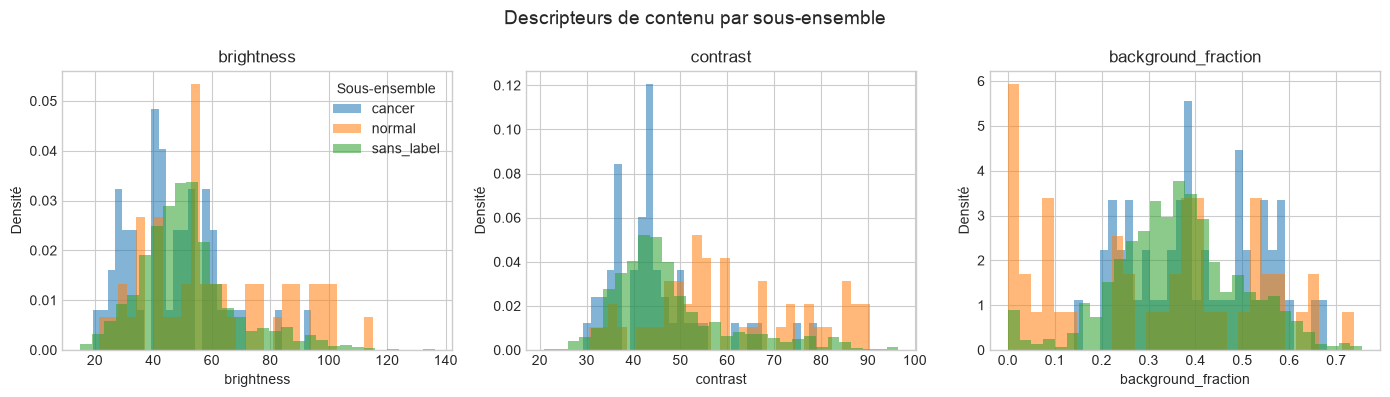

In [3]:
descriptor_columns = ["brightness", "contrast", "background_fraction"]

display(manifest.groupby("subset")[descriptor_columns].median().round(2))

figure, axes = plt.subplots(1, 3, figsize=(14, 4))
for axis, column in zip(axes, descriptor_columns, strict=True):
    for subset, group in manifest.groupby("subset"):
        axis.hist(
            group[column],
            bins=30,
            alpha=0.55,
            density=True,
            label=subset,
        )
    axis.set(title=column, xlabel=column, ylabel="Densité")
axes[0].legend(title="Sous-ensemble")
figure.suptitle("Descripteurs de contenu par sous-ensemble", fontsize=14)
plt.tight_layout()
figure.savefig(
    FIGURES_DIR / "descripteurs-images.png", dpi=120, bbox_inches="tight"
)
plt.show()

### Images atypiques

On affiche les images aux valeurs extrêmes pour décider s'il faut les écarter : les images en couleur, les plus sombres, les plus lumineuses et celles avec le plus de fond.

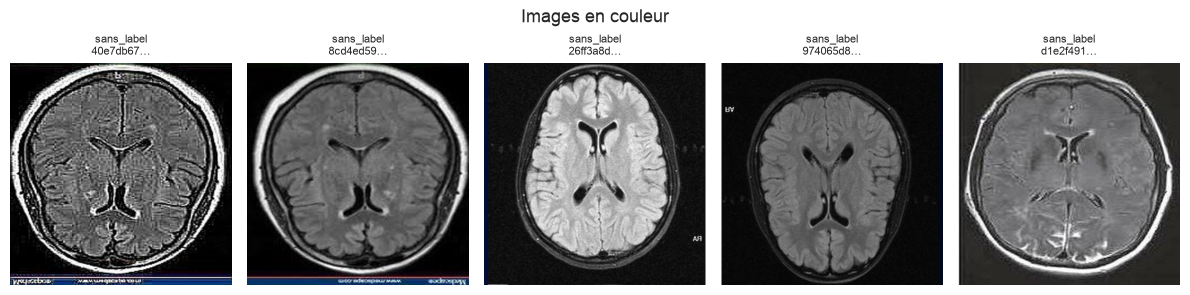

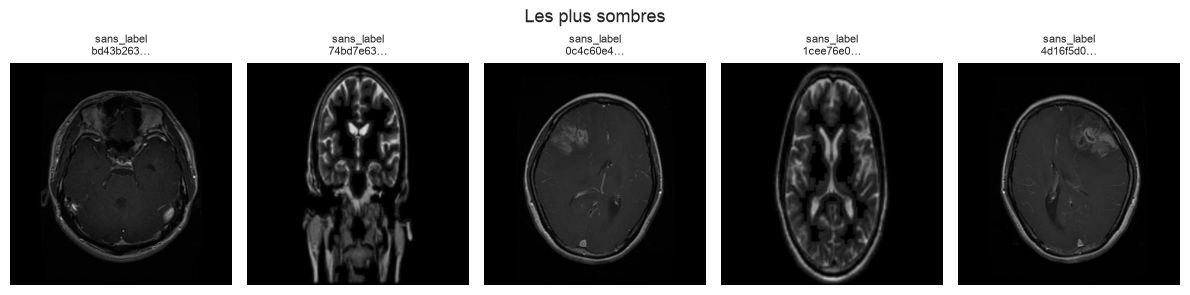

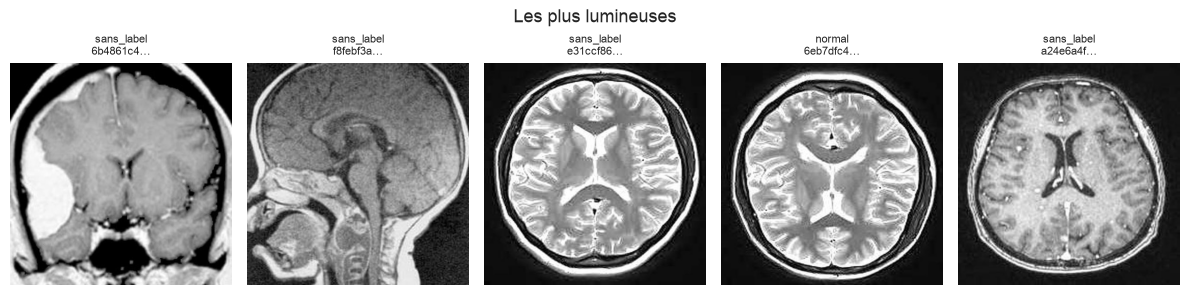

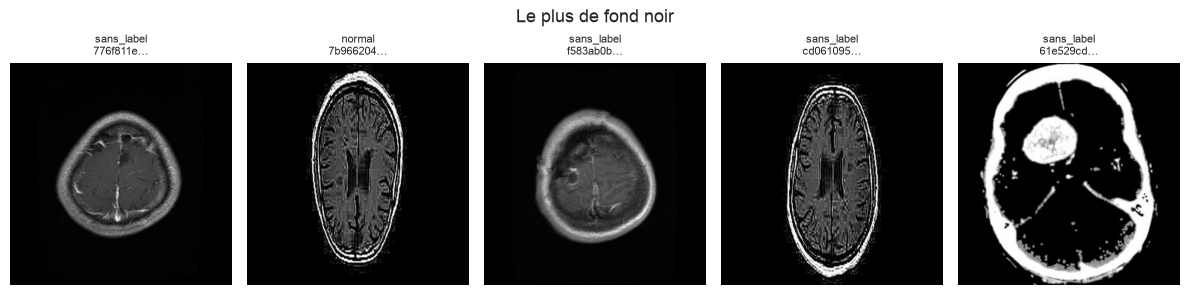

Images en couleur annotées : 1


In [4]:
N_ATYPICAL = 5

atypical_groups = {
    "couleur": (
        "Images en couleur",
        manifest.nlargest(N_ATYPICAL, "channel_gap"),
    ),
    "sombres": (
        "Les plus sombres",
        manifest.nsmallest(N_ATYPICAL, "brightness"),
    ),
    "lumineuses": (
        "Les plus lumineuses",
        manifest.nlargest(N_ATYPICAL, "brightness"),
    ),
    "fond": (
        "Le plus de fond noir",
        manifest.nlargest(N_ATYPICAL, "background_fraction"),
    ),
}

for slug, (title, group) in atypical_groups.items():
    figure, axes = plt.subplots(1, N_ATYPICAL, figsize=(2.4 * N_ATYPICAL, 3.1))
    for axis, (_, row) in zip(axes, group.iterrows(), strict=True):
        with Image.open(row["filepath"]) as image:
            axis.imshow(image)
        axis.set_title(f"{row['subset']}\n{row['image_id'][:8]}…", fontsize=8)
        axis.axis("off")
    figure.suptitle(title, fontsize=13)
    plt.tight_layout()
    figure.savefig(
        FIGURES_DIR / f"images-atypiques-{slug}.png",
        dpi=120,
        bbox_inches="tight",
    )
    plt.show()

print(
    "Images en couleur annotées :",
    manifest.loc[manifest["is_color"], "is_labeled"].sum(),
)

### Image inexploitable

En inspectant les images les plus lumineuses, une image **inexploitable** a été repérée : une tache blanche saturée, avec des artefacts visuels et aucun détail anatomique. Ses caractéristiques ne seraient que du bruit pour le modèle. C'est la **seule image aberrante retirée** : toutes les autres images atypiques sont de vraies IRM lisibles, donc conservées. Cette image est non annotée, le jeu annoté ne change donc pas. Elle est exclue du manifeste par `brain_mri.dataset` (`EXCLUDED_IMAGES`) et le fichier brut n'est pas modifié.

,image_id,subset,reason
1197,ca4c389b-8e9b-40d0-b149-1c81934ea251,sans_label,"saturée, sans détail anatomique exploitable"


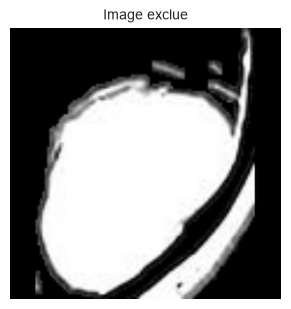

1 image exclue, absente du manifeste : 98 annotées et 1,386 images au total.


In [5]:
inventory = build_inventory(RAW_DATA_DIR)
excluded = inventory.loc[inventory["image_id"].isin(EXCLUDED_IMAGES)].assign(
    reason=lambda frame: frame["image_id"].map(EXCLUDED_IMAGES)
)
display(excluded[["image_id", "subset", "reason"]])
assert not manifest["image_id"].isin(EXCLUDED_IMAGES).any()

figure, axis = plt.subplots(figsize=(3.5, 3.7))
with Image.open(excluded["filepath"].iloc[0]) as image:
    axis.imshow(image)
axis.set_title("Image exclue", fontsize=10)
axis.axis("off")
plt.show()

print(
    f"{len(excluded)} image exclue, absente du manifeste : "
    f"{manifest['is_labeled'].sum()} annotées et {len(manifest):,} images "
    "au total."
)

## 3. Prétraitement

Le modèle retenu est un **ResNet50 pré-entraîné sur ImageNet**, dont les couches convolutives sont **gelées** : il ne sert qu'à produire des caractéristiques. Les images sont déjà carrées (512 × 512). Le prétraitement comporte quatre étapes :

1. **Conversion en niveaux de gris.** Une IRM est une image d'intensité : 1 377 images sur 1 387 sont déjà en niveaux de gris. Les couleurs des 10 autres sont des artefacts (par exemple des bandeaux de texte colorés) qui ne portent aucune information médicale et donneraient au modèle un indice parasite. Le canal gris est recopié sur trois canaux, car le ResNet attend du RGB.
2. **Égalisation d'histogramme**, appliquée à chaque image en pleine résolution. Elle redistribue les niveaux de gris pour que leur histogramme soit à peu près uniforme, ce qui gomme les différences globales de luminosité et de contraste. Ces deux grandeurs suffisent à elles seules à séparer les classes annotées : c'est un indice parasite à neutraliser (la justification chiffrée est en section 6).
3. **Redimensionnement** à 224 × 224 (attendu par le ResNet), sans rognage, pour ne couper aucune anatomie en bordure.
4. **Normalisation** avec la moyenne et l'écart-type d'ImageNet, repris des transformations officielles des poids (`weights.transforms()`), car c'est la distribution sur laquelle le modèle a été entraîné.

Ces étapes sont implémentées dans `brain_mri.features` (`preprocess_equalized`).

Les étapes 1 et 2 ont un but précis : **réduire les biais liés à l'image**, c'est-à-dire des indices comme la couleur, la luminosité ou le contraste qui permettraient au modèle de deviner le label sans regarder la pathologie. Les étapes 3 et 4 adaptent simplement l'image au modèle.

Moyenne ImageNet : [0.485, 0.456, 0.406]
Écart-type ImageNet : [0.229, 0.224, 0.225]


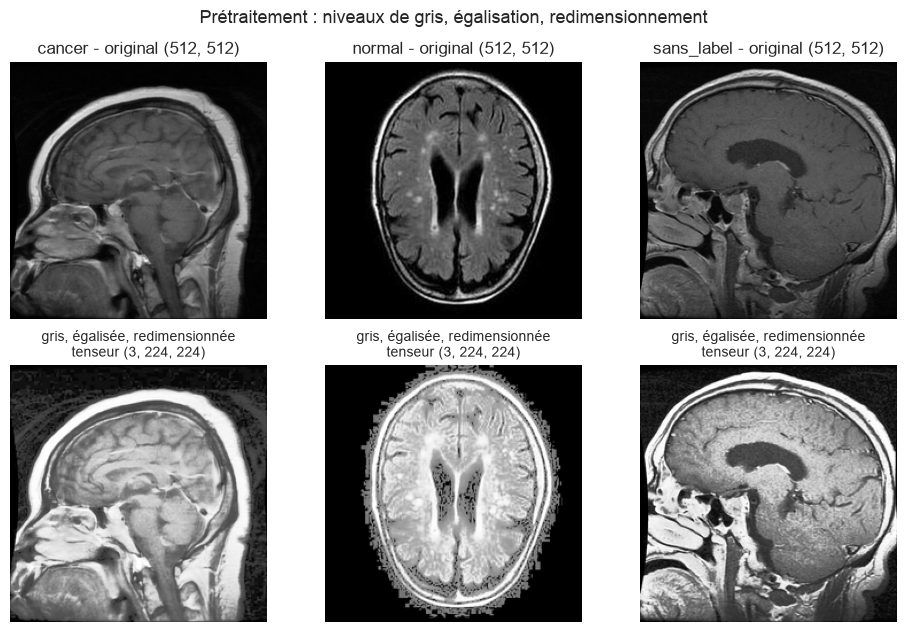

Tenseur normalisé : moyenne 0.20, écart-type 1.24 (dernière image affichée)


In [6]:
# Niveaux de gris et égalisation : réduction des biais liés à l'image
# (couleur, luminosité, contraste), voir la justification en section 6.
preprocess = preprocess_equalized

print("Moyenne ImageNet :", IMAGENET_MEAN)
print("Écart-type ImageNet :", IMAGENET_STD)

samples = manifest.groupby("subset").head(1)
figure, axes = plt.subplots(2, len(samples), figsize=(3.2 * len(samples), 6.4))
for column, (_, row) in enumerate(samples.iterrows()):
    with Image.open(row["filepath"]) as image:
        tensor = preprocess(image)
        axes[0, column].imshow(image.convert("RGB"))
        axes[0, column].set_title(f"{row['subset']} - original {image.size}")
        equalized = ImageOps.equalize(image.convert("L"))
        resized = equalized.resize(
            (IMAGE_SIZE, IMAGE_SIZE), Image.Resampling.LANCZOS
        )
        axes[1, column].imshow(resized, cmap="gray", vmin=0, vmax=255)
        axes[1, column].set_title(
            f"gris, égalisée, redimensionnée\ntenseur {tuple(tensor.shape)}",
            fontsize=10,
        )
    axes[0, column].axis("off")
    axes[1, column].axis("off")
figure.suptitle(
    "Prétraitement : niveaux de gris, égalisation, redimensionnement",
    fontsize=13,
)
plt.tight_layout()
figure.savefig(FIGURES_DIR / "pretraitement.png", dpi=120, bbox_inches="tight")
plt.show()

print(
    f"Tenseur normalisé : moyenne {tensor.mean():.2f}, "
    f"écart-type {tensor.std():.2f} (dernière image affichée)"
)

## 4. Extraction des caractéristiques

L'extraction est implémentée dans `brain_mri.features` (`load_extractor`, `extract_features`). On prélève la sortie de deux couches du ResNet50 et on la résume par un **average pooling global**, ce qui donne un vecteur par image :

| Couche | Rôle | Dimension |
|---|---|---|
| `layer3` | Caractéristiques de niveau intermédiaire (textures, motifs) | 1 024 |
| `layer4` | Caractéristiques de haut niveau, dernière couche convolutive | 2 048 |

Comparer deux couches permet de choisir celle qui sépare le mieux les images annotées, comme le recommande la mission.

In [7]:
device = select_device()
print(f"Calcul sur : {device}")

extractor = load_extractor(device)

start = time.perf_counter()
features = extract_features(extractor, manifest["filepath"], device)
elapsed = time.perf_counter() - start

for name, matrix in features.items():
    print(f"{name} : {matrix.shape}, {matrix.dtype}")
images_per_second = len(manifest) / elapsed
print(f"{elapsed:.1f} s, soit {images_per_second:.1f} images par seconde")

Calcul sur : mps
layer3 : (1386, 1024), float32
layer4 : (1386, 2048), float32
9.5 s, soit 145.6 images par seconde


## 5. Sauvegarde

Chaque couche est enregistrée dans un fichier `.npz` qui contient les `image_id` **et** la matrice de features : l'alignement avec le manifeste reste ainsi dans un seul fichier.

In [8]:
saved_paths = save_features(manifest["image_id"], features)

# Relecture : les identifiants et la matrice doivent être identiques.
for matrix, path in zip(features.values(), saved_paths, strict=True):
    saved_ids, saved_matrix = load_features(path)
    assert (saved_ids == manifest["image_id"].to_numpy()).all()
    assert np.array_equal(saved_matrix, matrix)
print("Relecture réussie : identifiants et matrices identiques.")

Relecture réussie : identifiants et matrices identiques.


## 6. Vérification de l'exploitabilité

Avant de passer au clustering, on vérifie que les vecteurs sont valides, puis on compare les deux couches sur les **images annotées**, avec deux mesures :

- le **score de silhouette** des labels (cosinus), qui vaut 1 si les classes sont bien séparées et 0 si elles se recouvrent ;
- l'**écart de similarité cosinus** : similarité moyenne entre images de même classe moins similarité moyenne entre classes différentes.

Avec seulement 98 images annotées, ces mesures sont indicatives : elles servent à comparer les couches, pas à estimer une performance.

In [9]:
labeled = manifest["is_labeled"].to_numpy()
labels = manifest.loc[labeled, "label"].to_numpy()

rows = []
for name, matrix in features.items():
    labeled_matrix = matrix[labeled]
    normalized = labeled_matrix / np.linalg.norm(
        labeled_matrix, axis=1, keepdims=True
    )
    similarity = normalized @ normalized.T
    same_class = labels[:, None] == labels[None, :]
    off_diagonal = ~np.eye(len(labels), dtype=bool)
    rows.append(
        {
            "couche": name,
            "dimension": matrix.shape[1],
            "valeurs_non_finies": int((~np.isfinite(matrix)).sum()),
            "dimensions_constantes": int((matrix.std(axis=0) == 0).sum()),
            "norme_moyenne": np.linalg.norm(matrix, axis=1).mean(),
            "silhouette_cosinus": silhouette_score(
                labeled_matrix, labels, metric="cosine"
            ),
            "ecart_cosinus": similarity[same_class & off_diagonal].mean()
            - similarity[~same_class].mean(),
        }
    )

comparison = pd.DataFrame(rows).set_index("couche").round(3)
display(comparison)

,dimension,valeurs_non_finies,dimensions_constantes,norme_moyenne,silhouette_cosinus,ecart_cosinus
couche,,,,,,
layer3,1024,0,0,22.124001,0.193,0.015
layer4,2048,0,0,14.559000,0.136,0.056


### Les features portent-elles un signal ?

Deux preuves, sur les images annotées :

- une **projection PCA en 2D** (standardisation puis deux composantes), avec les images non annotées en gris pour situer les annotées dans l'ensemble ;
- un **modèle de référence** : une régression logistique évaluée par validation croisée stratifiée répétée, dont on retient l'AUC (0,5 = hasard).

La standardisation est placée **dans** la chaîne de traitement : elle est réajustée dans chaque pli, sans fuite d'information. Le label n'est converti en 0 / 1 que pour cette évaluation, sur les images annotées. Avec 98 images, ces mesures sont indicatives.

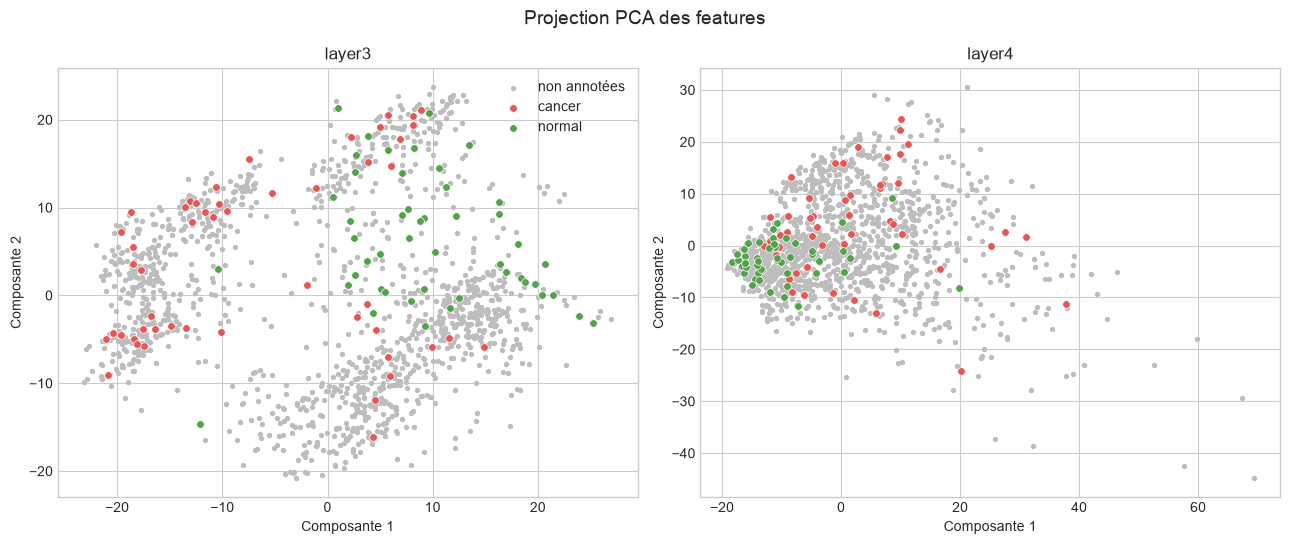

,auc_moyenne,ecart_type
couche,,
layer3,0.978,0.040
layer4,0.966,0.054


In [10]:
figure, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for axis, (name, matrix) in zip(axes, features.items(), strict=True):
    coordinates = PCA(n_components=2, random_state=0).fit_transform(
        StandardScaler().fit_transform(matrix)
    )
    axis.scatter(
        coordinates[~labeled, 0],
        coordinates[~labeled, 1],
        s=8,
        color="#BDBDBD",
        label="non annotées",
    )
    for label, color in (("cancer", "#E45756"), ("normal", "#54A24B")):
        mask = (manifest["label"] == label).to_numpy()
        axis.scatter(
            coordinates[mask, 0],
            coordinates[mask, 1],
            s=30,
            color=color,
            edgecolor="white",
            linewidth=0.5,
            label=label,
        )
    axis.set(title=name, xlabel="Composante 1", ylabel="Composante 2")
axes[0].legend()
figure.suptitle("Projection PCA des features", fontsize=14)
plt.tight_layout()
figure.savefig(FIGURES_DIR / "pca-features.png", dpi=120, bbox_inches="tight")
plt.show()

evaluation_target = (labels == "cancer").astype(int)
cross_validation = RepeatedStratifiedKFold(
    n_splits=5, n_repeats=10, random_state=42
)
baseline_rows = []
for name, matrix in features.items():
    model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
    scores = cross_val_score(
        model,
        matrix[labeled],
        evaluation_target,
        cv=cross_validation,
        scoring="roc_auc",
    )
    baseline_rows.append(
        {
            "couche": name,
            "auc_moyenne": scores.mean(),
            "ecart_type": scores.std(),
        }
    )
display(pd.DataFrame(baseline_rows).set_index("couche").round(3))

### Justification du prétraitement

On compare trois prétraitements sur les images annotées, avec le même modèle de référence que ci-dessus. La colonne « descripteurs seuls » donne l'AUC d'un modèle qui ne voit que la luminosité, le contraste et la part de fond, **calculés sur l'image après prétraitement** : elle mesure l'indice parasite qui reste. Si l'égalisation le réduit sans dégrader les embeddings, elle est justifiée.

In [11]:
def cross_validated_auc(matrix: np.ndarray) -> tuple[float, float]:
    """AUC moyenne et écart-type en validation croisée."""
    model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
    scores = cross_val_score(
        model,
        matrix,
        evaluation_target,
        cv=cross_validation,
        scoring="roc_auc",
    )
    return scores.mean(), scores.std()


def gray_descriptors(filepath, equalize: bool) -> tuple[float, float, float]:
    """Luminosité, contraste et part de fond d'une image en niveaux de gris."""
    with Image.open(filepath) as image:
        gray = image.convert("L")
        if equalize:
            gray = ImageOps.equalize(gray)
        pixels = np.asarray(gray, dtype=float)
    return (
        pixels.mean(),
        pixels.std(),
        (pixels < BACKGROUND_LEVEL).mean(),
    )


variants = {
    "RGB d'origine": (preprocess_rgb, False),
    "Niveaux de gris": (preprocess_gray, False),
    "Niveaux de gris + égalisation (retenu)": (preprocess_equalized, True),
}
labeled_paths = manifest.loc[labeled, "filepath"]

comparison_rows = []
for variant_name, (transform, equalize) in variants.items():
    row = {"prétraitement": variant_name}
    variant_features = extract_features(
        extractor, labeled_paths, device, transform
    )
    for layer, matrix in variant_features.items():
        mean, std = cross_validated_auc(matrix)
        row[layer] = f"{mean:.3f} ± {std:.3f}"
    descriptors_matrix = np.array(
        [gray_descriptors(path, equalize) for path in labeled_paths]
    )
    mean, std = cross_validated_auc(descriptors_matrix)
    row["descripteurs seuls"] = f"{mean:.3f} ± {std:.3f}"
    comparison_rows.append(row)

display(pd.DataFrame(comparison_rows).set_index("prétraitement"))

,layer3,layer4,descripteurs seuls
prétraitement,,,
RGB d'origine,0.975 ± 0.038,0.954 ± 0.050,0.822 ± 0.078
Niveaux de gris,0.975 ± 0.038,0.955 ± 0.050,0.822 ± 0.078
Niveaux de gris + égalisation (retenu),0.978 ± 0.040,0.966 ± 0.054,0.657 ± 0.125


## 7. Coût de calcul

Le débit mesuré permet d'estimer le temps nécessaire pour un passage à l'échelle. Cette estimation sera reprise dans le support de présentation (4 millions d'images, budget de 5 000 €).

In [12]:
TARGET_IMAGES = 4_000_000

estimated_hours = TARGET_IMAGES / images_per_second / 3600
print(f"Débit mesuré : {images_per_second:.1f} images par seconde ({device})")
print(
    f"Extraction de {TARGET_IMAGES:,} images sur cette machine : "
    f"environ {estimated_hours:.0f} heures"
)

Débit mesuré : 145.6 images par seconde (mps)
Extraction de 4,000,000 images sur cette machine : environ 8 heures


## Conclusion de l'étape

### Synthèse

- **Prétraitement.** Les **1 386 images** retenues (le manifeste dédupliqué, sans l'image inexploitable) sont converties en niveaux de gris, égalisées par histogramme, redimensionnées en 224 × 224 puis normalisées avec les statistiques d'ImageNet, avant de passer dans un **ResNet50 gelé**. Deux matrices en résultent : `layer3` (1 387 × 1 024) et `layer4` (1 387 × 2 048). Elles sont sauvegardées en `.npz` avec les `image_id`, et la relecture est identique.
- Les vecteurs sont valides : aucune valeur non finie et aucune dimension constante.
- **Image exclue.** Une seule image est retirée, parce qu'elle est inexploitable : une tache blanche saturée, sans détail anatomique. Elle n'est pas annotée, donc les 98 images annotées sont toutes conservées. Les autres images atypiques sont de vraies IRM lisibles et restent dans le jeu.
- **10 images sont en couleur** (1 annotée `normal`, 9 non annotées). Elles sont conservées, car rien ne justifie de retirer une image annotée, et la conversion en niveaux de gris supprime leurs artefacts de couleur.
- Sur les images brutes, les descripteurs de contenu diffèrent d'une classe à l'autre : luminosité médiane de **43,6** pour `cancer` contre **55,3** pour `normal`, contraste médian de **42,8** contre **56,1**. Les images non annotées sont entre les deux (49,8 et 44,4).
- **Justification de l'égalisation.** Sur les images d'origine, un modèle qui ne voit que la luminosité, le contraste et la part de fond atteint une AUC de **0,822 ± 0,078** : ces indices suffisent à séparer en grande partie les classes annotées. Après égalisation, cette AUC tombe à **0,657 ± 0,125**, alors que celle des embeddings ne baisse pas (`layer3` : 0,978 contre 0,975 ; `layer4` : 0,966 contre 0,954). Le signal des embeddings ne vient donc pas surtout de la luminosité ni du contraste globaux. L'égalisation ne supprime pas tout le biais : il reste la part de fond, et elle ne corrige pas les différences de séquence ou de source d'acquisition.
- **Couches.** `layer3` a la meilleure silhouette (0,193 contre 0,136), `layer4` le meilleur écart de similarité cosinus (0,056 contre 0,015). Les valeurs sont faibles dans les deux cas, ce qui n'a rien d'anormal avec des caractéristiques ImageNet non adaptées à l'IRM et seulement 98 images annotées.
- **Exploitabilité.** La projection PCA montre une structure : les `normal` se regroupent plutôt d'un côté, les `cancer` de l'autre, avec un recouvrement. Un modèle linéaire de référence, évalué par validation croisée sur les images annotées, atteint une AUC de **0,978 ± 0,040** sur `layer3` et **0,966 ± 0,054** sur `layer4` : les features portent un signal. `layer3` est légèrement devant, mais l'écart est inférieur à l'écart-type.
- Le débit mesuré est de **143,2 images par seconde** (GPU Apple, calcul MPS), soit environ **8 heures** pour 4 millions d'images sur cette machine.

### Décision

Le prétraitement retenu est : niveaux de gris, égalisation d'histogramme, redimensionnement, normalisation ImageNet. Les deux couches sont conservées pour l'étape suivante, et aucune image annotée n'est retirée. À surveiller lors du clustering : des groupes pourraient encore refléter des différences de source ou de contraste plutôt que la pathologie.